In [ ]:
# import pandas as pd
# import requests
# import io
# from pathlib import Path
# import time

# OUT = Path("scan_independent_data")
# OUT.mkdir(exist_ok=True)

# # Format: "StationID:State:Network"
# # You can find exact stations near your boxes using the USDA NRCS Interactive Map:
# # https://www.nrcs.usda.gov/wps/portal/wcc/home/quicklinks/imap
# scan_stations = {
#     "2033:VA:SCAN": "Shenandoah_VA",      # Near your VA box
#     "2070:VA:SCAN": "Prince_Edward_VA",   # Central VA
#     "2005:TX:SCAN": "Prairie_View_TX",    # TX
#     "2189:TX:SCAN": "Spur_TX"             # Just south of Fort Worth!
# }

# START_DATE = "2002-01-01"
# END_DATE = "2026-10-19"

# # AWDB API Elements:
# # TOBS = Temperature Observed (Celsius)
# # RHUM = Relative Humidity (%)
# # PRES = Barometric Pressure (Often missing, but included just in case)
# # PRCP = Precipitation 
# ELEMENTS = "TOBS,RHUM,PRES,PRCP"

# all_data = []

# for site_id, site_name in scan_stations.items():
#     print(f"Downloading USDA SCAN data for {site_name}...")
    
#     # The USDA AWDB CSV Report Generator URL
#     url = f"https://wcc.sc.egov.usda.gov/reportGenerator/view_csv/customSingleStationReport/hourly/{site_id}/{START_DATE},{END_DATE}/{ELEMENTS}"
    
#     try:
#         r = requests.get(url, timeout=120)
#         r.raise_for_status()
        
#         # The USDA CSV has a header block that starts with '#'. We tell Pandas to ignore these lines.
#         df = pd.read_csv(io.StringIO(r.text), comment='#')
        
#         # Clean up column names (USDA adds units to the column headers)
#         df.columns = [c.split('(')[0].strip().lower().replace(' ', '_') for c in df.columns]
        
#         # Standardize
#         df = df.rename(columns={
#             'date': 'datetime',
#             'air_temperature_observed': 'temperature',
#             'relative_humidity': 'relative_humidity',
#             'barometric_pressure': 'station_pressure',
#             'precipitation_accumulation': 'precip_accum'
#         })
        
#         df['datetime'] = pd.to_datetime(df['datetime'], errors='coerce', utc=True)
#         df['station_id'] = site_id
#         df['station_name'] = site_name
        
#         # Save individual station
#         df.to_csv(OUT / f"{site_name}_SCAN_hourly.csv", index=False)
#         all_data.append(df)
#         print(f"  -> Saved {len(df):,} rows.")
        
#     except Exception as e:
#         print(f"  -> Failed to download {site_name}: {e}")
        
#     time.sleep(2) # Be polite to the USDA server

# if all_data:
#     combined = pd.concat(all_data, ignore_index=True)
#     combined.to_csv(OUT / "all_scan_independent_observations.csv", index=False)
#     print(f"\nFinished! Total independent observations: {len(combined):,}")

  -> Failed to download Shenandoah_VA: No columns to parse from file
  -> Failed to download Prince_Edward_VA: No columns to parse from file
  -> Failed to download Prairie_View_TX: No columns to parse from file
  -> Failed to download Spur_TX: No columns to parse from file


In [6]:
import pandas as pd
import numpy as np
import requests
import io
from pathlib import Path
import time

OUT = Path("uscrn_independent_data")
OUT.mkdir(exist_ok=True)

uscrn_stations = [
    "VA_Charlottesville_2_SSE",
    "TX_Palestine_6_WNW",
   "TX_Bronte_11_NNE"
]

START_YEAR = 2002
END_YEAR = 2026

all_uscrn = []

for station in uscrn_stations:
    print(f"Processing USCRN: {station}")
    station_data = []
    
    for year in range(START_YEAR, END_YEAR + 1):
        url = f"https://www.ncei.noaa.gov/pub/data/uscrn/products/hourly02/{year}/CRNH0203-{year}-{station}.txt"
        
        try:
            r = requests.get(url, timeout=30)
            if r.status_code == 404:
                continue # Station didn't exist in this specific year, skip silently
            r.raise_for_status()
            
            # Use header=None to prevent Pandas from shifting columns if NOAA added sensors
            df = pd.read_csv(io.StringIO(r.text), sep=r'\s+', header=None, dtype=str)
            
            # USCRN Official Column Indices (0-indexed):
            # Column 1: UTC_DATE (YYYYMMDD)
            # Column 2: UTC_TIME (HHmm)
            # Column 6: LONGITUDE
            # Column 7: LATITUDE
            # Column 8: T_CALC (Temperature Celsius)
            # Column 12: P_CALC (Precipitation mm)
            # Column 21: RH_HR_AVG (Relative Humidity %)
            
            # Safely combine date and time strings
            date_strings = df[1] + df[2].str.zfill(4)
            df['datetime'] = pd.to_datetime(date_strings, format='%Y%m%d%H%M', errors='coerce', utc=True)
            
            # Drop rows where the timestamp was legitimately broken
            df = df.dropna(subset=['datetime']).copy()
            
            if df.empty:
                continue
                
            # Extract and convert the exact columns we need
            clean_df = pd.DataFrame({
                'datetime': df['datetime'],
                'station_name': station,
                'latitude': pd.to_numeric(df[7], errors='coerce'),
                'longitude': pd.to_numeric(df[6], errors='coerce'),
                'temperature': pd.to_numeric(df[8], errors='coerce'),
                'relative_humidity': pd.to_numeric(df[21], errors='coerce'),
                'precipitation': pd.to_numeric(df[12], errors='coerce')
            })
            
            # Clean NOAA's -9999 missing data flags
            for col in ['latitude', 'longitude', 'temperature', 'relative_humidity', 'precipitation']:
                clean_df.loc[clean_df[col] <= -999, col] = np.nan
                
            station_data.append(clean_df)
            
        except Exception as e:
            print(f"  Error on {year}: {e}")
            
        time.sleep(0.2)
        
    if station_data:
        st_df = pd.concat(station_data, ignore_index=True)
        # Drop completely duplicate hours if any exist
        st_df = st_df.drop_duplicates(subset=['datetime']).sort_values('datetime')
        st_df.to_csv(OUT / f"{station}_USCRN_hourly.csv", index=False)
        all_uscrn.append(st_df)
        print(f"  -> Saved {len(st_df):,} rows.")
    else:
        print(f"  -> No data found for {station} across all years.")

if all_uscrn:
    final_uscrn = pd.concat(all_uscrn, ignore_index=True)
    final_uscrn.to_csv(OUT / "all_uscrn_independent_observations.csv", index=False)
    print("\nAll USCRN downloads complete! The data is clean and ready for NLDAS-3 comparison.")
else:
    print("No data was downloaded. Check your internet connection or the station names.")

Processing USCRN: VA_Charlottesville_2_SSE
  -> Saved 171,461 rows.
Processing USCRN: TX_Palestine_6_WNW
  -> Saved 205,148 rows.
Processing USCRN: TX_Bronte_11_NNE
  -> Saved 173,947 rows.

All USCRN downloads complete! The data is clean and ready for NLDAS-3 comparison.


Loading data from uscrn_independent_data/all_uscrn_independent_observations.csv...
Plotting station: VA_Charlottesville_2_SSE...
  -> No data found for VA_Charlottesville_2_SSE in 2004. Skipping.
Plotting station: TX_Palestine_6_WNW...


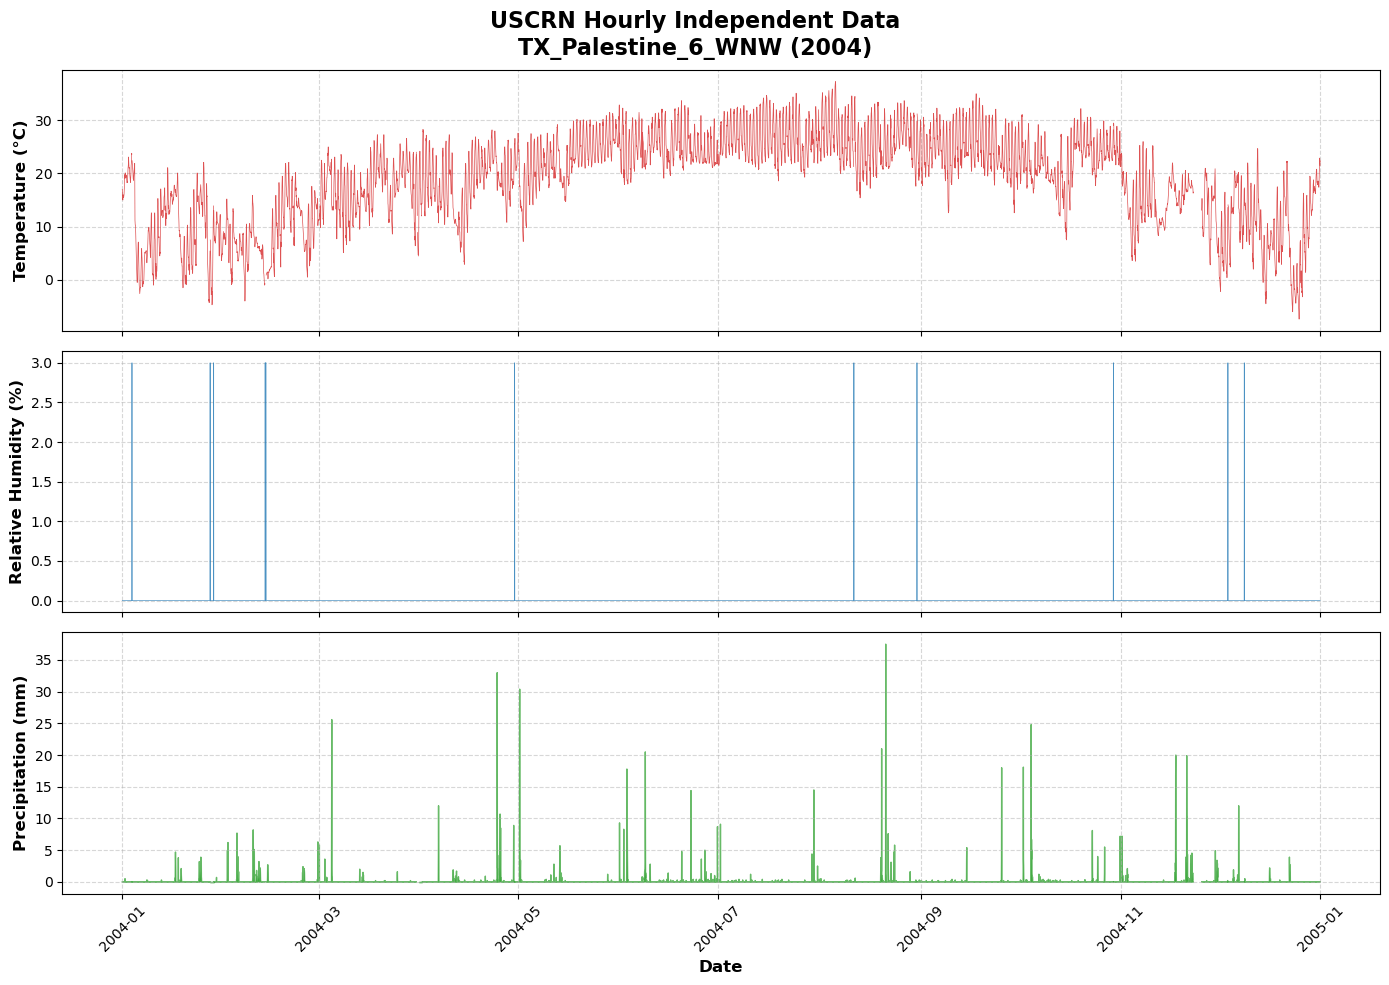

Plotting station: TX_Bronte_11_NNE...
  -> No data found for TX_Bronte_11_NNE in 2004. Skipping.


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Setup paths and load the combined USCRN data
DATA_FILE = Path("uscrn_independent_data/all_uscrn_independent_observations.csv")

print(f"Loading data from {DATA_FILE}...")
df = pd.read_csv(DATA_FILE)

# Convert datetime from string to actual Pandas datetime objects
df['datetime'] = pd.to_datetime(df['datetime'])

# ==========================================
# CONFIGURATION
# ==========================================
# TOGGLE THIS: 
# Set to a specific year (e.g., 2010) to zoom in, or set to None to plot all 20+ years.
ZOOM_YEAR = 2004  

# ==========================================
# PLOTTING LOOP
# ==========================================
stations = df['station_name'].unique()

for station in stations:
    print(f"Plotting station: {station}...")
    
    # Filter data for this specific station
    st_df = df[df['station_name'] == station].copy()
    
    # Apply zoom if requested
    if ZOOM_YEAR:
        st_df = st_df[st_df['datetime'].dt.year == ZOOM_YEAR]
        time_title = f"({ZOOM_YEAR})"
    else:
        time_title = "(All Time)"
        
    if st_df.empty:
        print(f"  -> No data found for {station} in {ZOOM_YEAR}. Skipping.")
        continue

    # Create a figure with 3 stacked subplots that share the same X-axis (Dates)
    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
    fig.suptitle(f"USCRN Hourly Independent Data\n{station} {time_title}", fontsize=16, fontweight='bold')

    # --- Plot 1: Temperature ---
    ax1.plot(st_df['datetime'], st_df['temperature'], color='tab:red', linewidth=0.5, alpha=0.8)
    ax1.set_ylabel("Temperature (°C)", fontsize=12, fontweight='bold')
    ax1.grid(True, linestyle="--", alpha=0.5)
    
    # If looking at all time, the gaps (NaNs) will naturally show as blank spaces in the line!

    # --- Plot 2: Relative Humidity ---
    ax2.plot(st_df['datetime'], st_df['relative_humidity'], color='tab:blue', linewidth=0.5, alpha=0.8)
    ax2.set_ylabel("Relative Humidity (%)", fontsize=12, fontweight='bold')
    ax2.grid(True, linestyle="--", alpha=0.5)

    # --- Plot 3: Precipitation ---
    # We use fill_between for precipitation because it looks like a clean bar chart but renders 100x faster
    ax3.fill_between(st_df['datetime'], st_df['precipitation'], 0, color='tab:green', alpha=0.7)
    ax3.set_ylabel("Precipitation (mm)", fontsize=12, fontweight='bold')
    ax3.set_xlabel("Date", fontsize=12, fontweight='bold')
    ax3.grid(True, linestyle="--", alpha=0.5)

    # Format the layout so it looks nice
    plt.xticks(rotation=45)
    plt.tight_layout()
    
    # Show the plot
    plt.show()

In [ ]:
import pandas as pd
import numpy as np
import requests
import io
import re
from pathlib import Path
import time
from tqdm import tqdm

OUT = Path("uscrn_independent_data")
OUT.mkdir(exist_ok=True)

# ==========================================
# CONFIGURATION
# ==========================================
START_YEAR = 2002
END_YEAR = 2026

# Put state abbreviations here to only download specific states (e.g., ["TX", "VA"]). 
# Leave the list empty [] to download ALL 130+ stations across the entire USA!
STATES_TO_PULL = [] 

# ==========================================
# 1. AUTO-DISCOVER STATION NAMES
# ==========================================
print("Connecting to NOAA to discover active USCRN stations...")
# We check a recent year (2023) to see all stations that are actively reporting
dir_url = "https://www.ncei.noaa.gov/pub/data/uscrn/products/hourly02/2023/"
r_dir = requests.get(dir_url, timeout=30)
r_dir.raise_for_status()

# Use regex to extract the exact station names from the file list
# NOAA files look like: CRNH0203-2023-TX_Palestine_6_WNW.txt
found_stations = list(set(re.findall(r'CRNH0203-2023-(.*?)\.txt', r_dir.text)))
found_stations.sort()

# Filter by state if requested
if STATES_TO_PULL:
    # The station string always starts with the state abbreviation (e.g., "TX_...")
    uscrn_stations = [s for s in found_stations if s.split('_')[0] in STATES_TO_PULL]
else:
    uscrn_stations = found_stations

print(f"Found {len(uscrn_stations)} stations to process!")
if STATES_TO_PULL:
    print(f"Filtered to states: {STATES_TO_PULL}")

# ==========================================
# 2. DOWNLOAD DATA
# ==========================================
all_uscrn = []

# Using tqdm to show a progress bar since 130 stations will take about 15-20 minutes
for station in tqdm(uscrn_stations, desc="Downloading USCRN Stations"):
    station_data = []
    
    for year in range(START_YEAR, END_YEAR + 1):
        url = f"https://www.ncei.noaa.gov/pub/data/uscrn/products/hourly02/{year}/CRNH0203-{year}-{station}.txt"
        
        try:
            r = requests.get(url, timeout=30)
            if r.status_code == 404:
                continue # Station didn't exist in this specific year, skip silently
            r.raise_for_status()
            
            # Use header=None to prevent Pandas from shifting columns 
            df = pd.read_csv(io.StringIO(r.text), sep=r'\s+', header=None, dtype=str)
            
            # Combine date and time strings safely
            date_strings = df[1] + df[2].str.zfill(4)
            df['datetime'] = pd.to_datetime(date_strings, format='%Y%m%d%H%M', errors='coerce', utc=True)
            
            # Drop rows where the timestamp was broken
            df = df.dropna(subset=['datetime']).copy()
            
            if df.empty:
                continue
                
            # Extract exactly the columns we need using NOAA's index
            clean_df = pd.DataFrame({
                'datetime': df['datetime'],
                'station_name': station,
                'latitude': pd.to_numeric(df[7], errors='coerce'),
                'longitude': pd.to_numeric(df[6], errors='coerce'),
                'temperature': pd.to_numeric(df[8], errors='coerce'),
                'relative_humidity': pd.to_numeric(df[21], errors='coerce'),
                'precipitation': pd.to_numeric(df[12], errors='coerce')
            })
            
            # Clean NOAA's -9999 missing data flags
            for col in ['latitude', 'longitude', 'temperature', 'relative_humidity', 'precipitation']:
                clean_df.loc[clean_df[col] <= -999, col] = np.nan
                
            station_data.append(clean_df)
            
        except Exception as e:
            pass # Silently pass to avoid cluttering the progress bar
            
        time.sleep(0.15) # Be polite to NOAA servers
        
    if station_data:
        st_df = pd.concat(station_data, ignore_index=True)
        # Drop duplicates and sort
        st_df = st_df.drop_duplicates(subset=['datetime']).sort_values('datetime')
        st_df.to_csv(OUT / f"{station}_USCRN_hourly.csv", index=False)
        all_uscrn.append(st_df)

# ==========================================
# 3. SAVE MASTER FILE
# ==========================================
if all_uscrn:
    final_uscrn = pd.concat(all_uscrn, ignore_index=True)
    final_uscrn.to_csv(OUT / "all_uscrn_independent_observations.csv", index=False)
    print(f"\nAll USCRN downloads complete! Total rows: {len(final_uscrn):,}")
    print(f"Master file saved to: {OUT / 'all_uscrn_independent_observations.csv'}")
else:
    print("\nNo data was downloaded.")